In [ ]:
!pip -q install kaggle

import os
import time
import random
import shutil
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Flatten,
    Dense
)

from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

warnings.filterwarnings("ignore")

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.20.0
NumPy version: 2.1.3


In [ ]:
from google.colab import files

print("Upload your kaggle.json file.")
uploaded = files.upload()

Upload your kaggle.json file.


Saving kaggle.json to kaggle.json


In [ ]:
os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod(
    "/root/.kaggle/kaggle.json",
    0o600
)

print("Kaggle API configured.")

Kaggle API configured.


In [ ]:
!kaggle datasets download \
    -d phucthaiv02/butterfly-image-classification \
    -p /content

Dataset URL: https://www.kaggle.com/datasets/phucthaiv02/butterfly-image-classification
License(s): CC0-1.0
100% 226M/226M [00:02<00:00, 105MB/s]



In [ ]:
zip_files = [
    f for f in os.listdir("/content")
    if f.endswith(".zip")
]

print("Downloaded ZIP files:")
print(zip_files)

dataset_zip = "/content/" + zip_files[0]

with zipfile.ZipFile(dataset_zip, "r") as zip_ref:
    zip_ref.extractall("/content/butterfly_dataset")

print("Dataset extracted.")

Downloaded ZIP files:
['butterfly-image-classification.zip']
Dataset extracted.


In [ ]:
for root, dirs, files_list in os.walk("/content/butterfly_dataset"):

    level = root.replace(
        "/content/butterfly_dataset", ""
    ).count(os.sep)

    indent = " " * 4 * level

    print(
        indent + os.path.basename(root) + "/"
    )

    if level < 2:

        for file in files_list[:10]:

            print(
                indent + "    " + file
            )

butterfly_dataset/
    Testing_set.csv
    Training_set.csv
    test/
        Image_2447.jpg
        Image_516.jpg
        Image_505.jpg
        Image_1246.jpg
        Image_1226.jpg
        Image_533.jpg
        Image_2242.jpg
        Image_97.jpg
        Image_425.jpg
        Image_2784.jpg
    train/
        Image_4725.jpg
        Image_2447.jpg
        Image_516.jpg
        Image_505.jpg
        Image_1246.jpg
        Image_6309.jpg
        Image_1226.jpg
        Image_533.jpg
        Image_2242.jpg
        Image_97.jpg


In [ ]:
BASE_DIR = "/content/butterfly_dataset"

training_csv = None
train_dir = None
test_dir = None

for root, dirs, files_list in os.walk(BASE_DIR):

    if "Training_set.csv" in files_list:

        training_csv = os.path.join(
            root,
            "Training_set.csv"
        )

    if "train" in dirs:

        possible_train = os.path.join(
            root,
            "train"
        )

        if train_dir is None:
            train_dir = possible_train

    if "test" in dirs:

        possible_test = os.path.join(
            root,
            "test"
        )

        if test_dir is None:
            test_dir = possible_test


print("Training CSV:")
print(training_csv)

print("\nTrain directory:")
print(train_dir)

print("\nTest directory:")
print(test_dir)

Training CSV:
/content/butterfly_dataset/Training_set.csv

Train directory:
/content/butterfly_dataset/train

Test directory:
/content/butterfly_dataset/test


In [ ]:
df = pd.read_csv(training_csv)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(df.head(10))

Dataset shape: (6499, 2)

Columns:
['filename', 'label']

First 10 rows:


,filename,label
0,Image_1.jpg,SOUTHERN DOGFACE
1,Image_2.jpg,ADONIS
2,Image_3.jpg,BROWN SIPROETA
3,Image_4.jpg,MONARCH
4,Image_5.jpg,GREEN CELLED CATTLEHEART
5,Image_6.jpg,CAIRNS BIRDWING
6,Image_7.jpg,GREEN CELLED CATTLEHEART
7,Image_8.jpg,EASTERN DAPPLE WHITE
8,Image_9.jpg,BROWN SIPROETA
9,Image_10.jpg,RED POSTMAN


In [ ]:
number_of_classes = df["label"].nunique()
total_images = len(df)

print("Number of Classes:", number_of_classes)
print("Total Labeled Images:", total_images)

Number of Classes: 75
Total Labeled Images: 6499


In [ ]:
class_counts = (
    df["label"]
    .value_counts()
    .sort_index()
)

print("Number of classes:", len(class_counts))

display(
    class_counts.to_frame(
        name="Number of Images"
    )
)

Number of classes: 75


,Number of Images
label,
ADONIS,88
AFRICAN GIANT SWALLOWTAIL,75
AMERICAN SNOOT,74
AN 88,85
APPOLLO,90
...,...
ULYSES,84
VICEROY,81
WOOD SATYR,71


In [ ]:
smallest_count = class_counts.min()
largest_count = class_counts.max()

smallest_classes = class_counts[
    class_counts == smallest_count
]

largest_classes = class_counts[
    class_counts == largest_count
]

print("Smallest class count:", smallest_count)
print("Smallest class(es):")
print(smallest_classes)

print("\nLargest class count:", largest_count)
print("Largest class(es):")
print(largest_classes)

Smallest class count: 71
Smallest class(es):
label
WOOD SATYR    71
Name: count, dtype: int64

Largest class count: 131
Largest class(es):
label
MOURNING CLOAK    131
Name: count, dtype: int64


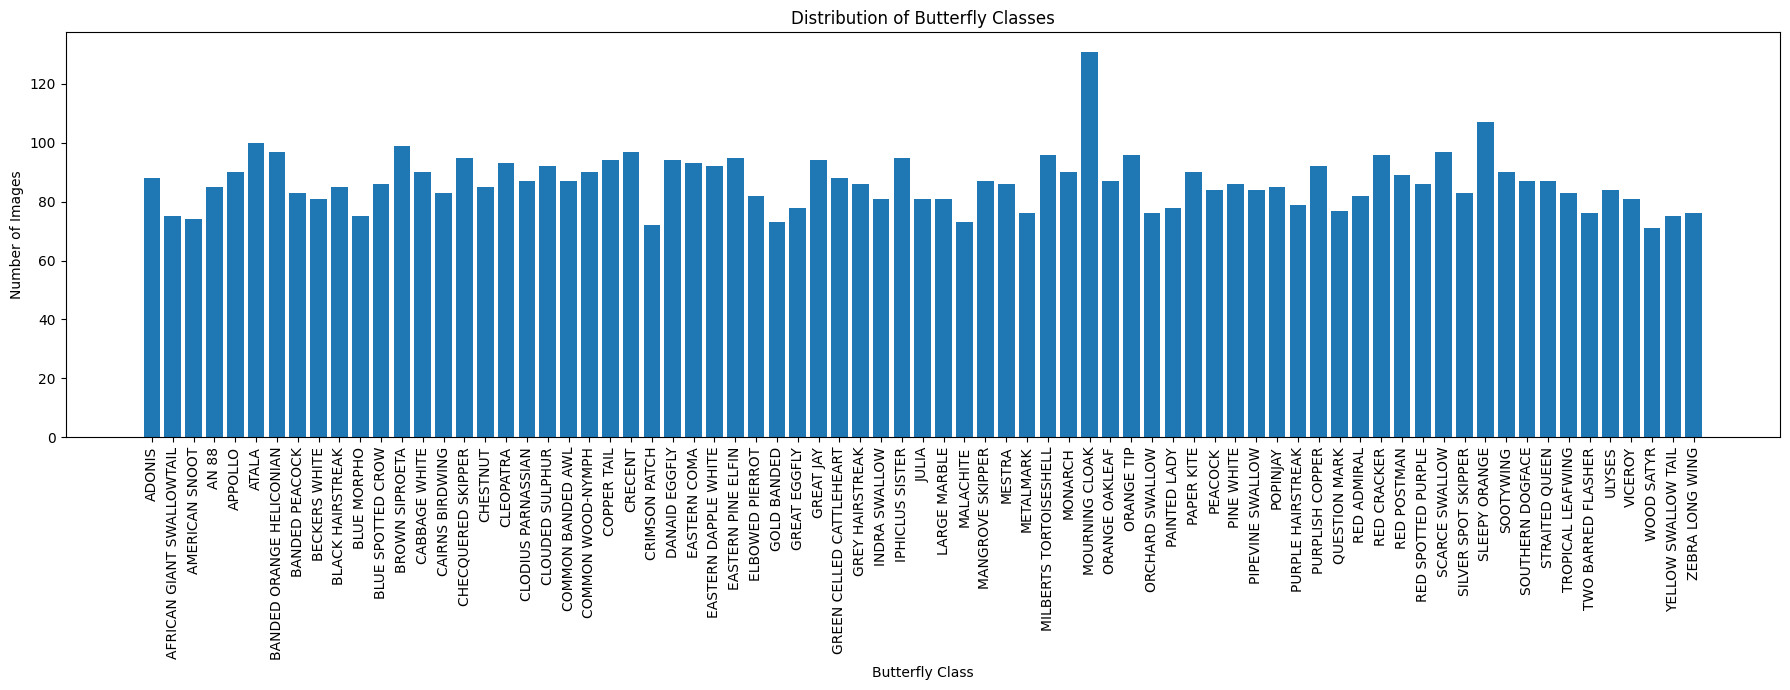

In [ ]:
plt.figure(figsize=(18, 7))

plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title(
    "Distribution of Butterfly Classes"
)

plt.xlabel(
    "Butterfly Class"
)

plt.ylabel(
    "Number of Images"
)

plt.xticks(
    rotation=90
)

plt.tight_layout()

plt.show()

In [ ]:
sample_filename = df.iloc[0]["filename"]

sample_path = os.path.join(
    train_dir,
    sample_filename
)

sample_image = Image.open(
    sample_path
)

print("Sample image:", sample_filename)
print("Format:", sample_image.format)
print("Dimensions:", sample_image.size)
print("Mode:", sample_image.mode)

Sample image: Image_1.jpg
Format: JPEG
Dimensions: (224, 224)
Mode: RGB


In [ ]:
dimensions = []
formats = []
modes = []

sample_size = min(
    1000,
    len(df)
)

sample_df = df.sample(
    sample_size,
    random_state=42
)

for _, row in sample_df.iterrows():

    path = os.path.join(
        train_dir,
        row["filename"]
    )

    try:

        img = Image.open(path)

        dimensions.append(
            img.size
        )

        formats.append(
            img.format
        )

        modes.append(
            img.mode
        )

    except:

        pass


dimension_counts = pd.Series(
    dimensions
).value_counts()

format_counts = pd.Series(
    formats
).value_counts()

mode_counts = pd.Series(
    modes
).value_counts()


print("Most common dimensions:")
print(dimension_counts.head())

print("\nImage formats:")
print(format_counts)

print("\nColor modes:")
print(mode_counts)

Most common dimensions:
(224, 224)    1000
Name: count, dtype: int64

Image formats:
JPEG    1000
Name: count, dtype: int64

Color modes:
RGB    1000
Name: count, dtype: int64


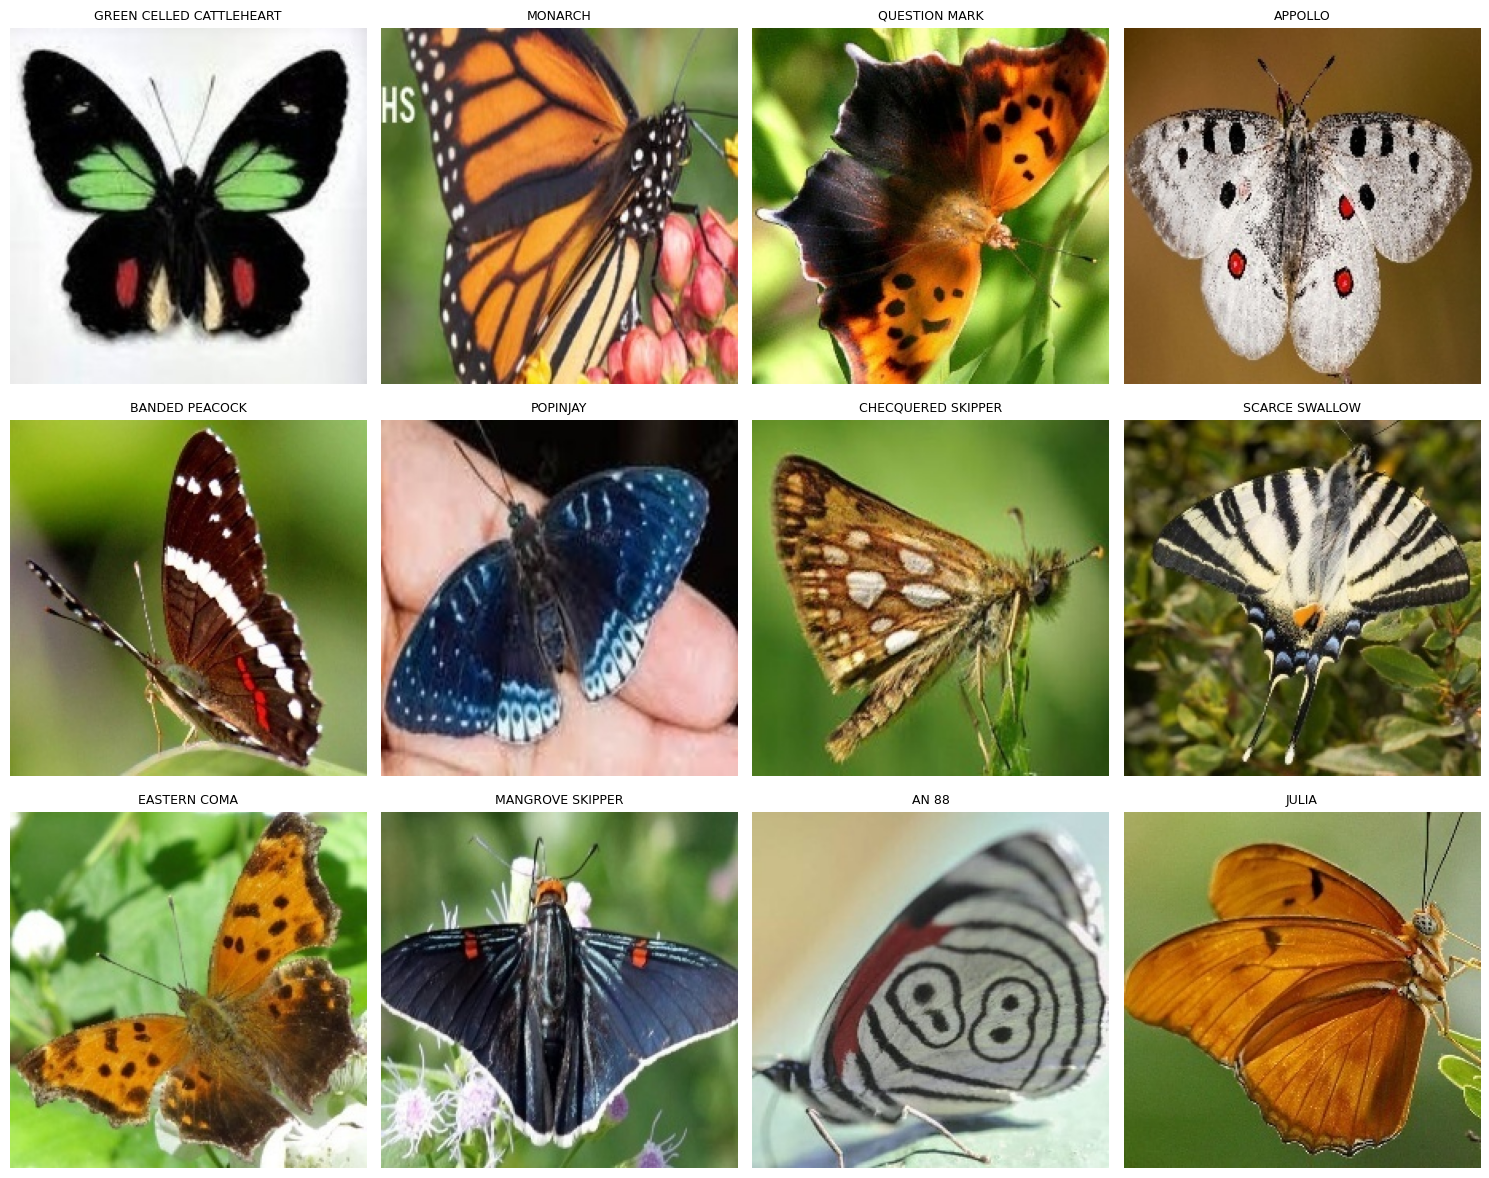

In [ ]:
sample_images = df.sample(
    12,
    random_state=42
)

plt.figure(
    figsize=(15, 12)
)

for i, (_, row) in enumerate(
    sample_images.iterrows()
):

    path = os.path.join(
        train_dir,
        row["filename"]
    )

    img = Image.open(path)

    plt.subplot(
        3,
        4,
        i + 1
    )

    plt.imshow(img)

    plt.title(
        row["label"],
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

train_df, temp_df = train_test_split(
    df,
    test_size=(VAL_RATIO + TEST_RATIO),
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)


print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print(
    "\nTotal:",
    len(train_df) +
    len(val_df) +
    len(test_df)
)

Training images: 4549
Validation images: 975
Testing images: 975

Total: 6499


In [ ]:
split_table = pd.DataFrame({
    "Dataset": [
        "Training",
        "Validation",
        "Testing",
        "Total"
    ],
    "Number of Images": [
        len(train_df),
        len(val_df),
        len(test_df),
        len(df)
    ],
    "Percentage": [
        len(train_df) / len(df) * 100,
        len(val_df) / len(df) * 100,
        len(test_df) / len(df) * 100,
        100
    ]
})

display(split_table)

,Dataset,Number of Images,Percentage
0,Training,4549,69.995384
1,Validation,975,15.002308
2,Testing,975,15.002308
3,Total,6499,100.000000


In [ ]:
NUM_CLASSES = number_of_classes

DENSE_UNITS = 128

ACTIVATION = "relu"

OUTPUT_ACTIVATION = "softmax"

OPTIMIZER = "adam"

LOSS_FUNCTION = "sparse_categorical_crossentropy"

EPOCHS = 10

BATCH_SIZE = 32

LEARNING_RATE = 0.001


print("Number of classes:", NUM_CLASSES)
print("Dense units:", DENSE_UNITS)
print("Activation:", ACTIVATION)
print("Optimizer:", OPTIMIZER)
print("Loss:", LOSS_FUNCTION)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

Number of classes: 75
Dense units: 128
Activation: relu
Optimizer: adam
Loss: sparse_categorical_crossentropy
Epochs: 10
Batch size: 32
Learning rate: 0.001


In [ ]:
from tensorflow.keras.utils import load_img, img_to_array


def load_dataset_images(
    dataframe,
    image_directory,
    image_size,
    class_to_index
):

    X = []
    y = []

    for _, row in dataframe.iterrows():

        image_path = os.path.join(
            image_directory,
            row["filename"]
        )

        try:

            img = load_img(
                image_path,
                target_size=(
                    image_size,
                    image_size
                ),
                color_mode="rgb"
            )

            img_array = img_to_array(
                img
            )

            img_array = (
                img_array / 255.0
            )

            X.append(
                img_array
            )

            y.append(
                class_to_index[
                    row["label"]
                ]
            )

        except Exception as e:

            print(
                "Error loading:",
                image_path
            )

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.int32)
    )

In [ ]:
class_names = sorted(
    df["label"].unique()
)

class_to_index = {
    name: index
    for index, name in enumerate(
        class_names
    )
}

index_to_class = {
    index: name
    for name, index in class_to_index.items()
}


print("Number of classes:", len(class_names))

print("\nFirst 10 class mappings:")

for name in class_names[:10]:

    print(
        class_to_index[name],
        "->",
        name
    )

Number of classes: 75

First 10 class mappings:
0 -> ADONIS
1 -> AFRICAN GIANT SWALLOWTAIL
2 -> AMERICAN SNOOT
3 -> AN 88
4 -> APPOLLO
5 -> ATALA
6 -> BANDED ORANGE HELICONIAN
7 -> BANDED PEACOCK
8 -> BECKERS WHITE
9 -> BLACK HAIRSTREAK


In [ ]:
class_names = sorted(
    df["label"].unique()
)

class_to_index = {
    name: index
    for index, name in enumerate(
        class_names
    )
}

index_to_class = {
    index: name
    for name, index in class_to_index.items()
}


print("Number of classes:", len(class_names))

print("\nFirst 10 class mappings:")

for name in class_names[:10]:

    print(
        class_to_index[name],
        "->",
        name
    )

Number of classes: 75

First 10 class mappings:
0 -> ADONIS
1 -> AFRICAN GIANT SWALLOWTAIL
2 -> AMERICAN SNOOT
3 -> AN 88
4 -> APPOLLO
5 -> ATALA
6 -> BANDED ORANGE HELICONIAN
7 -> BANDED PEACOCK
8 -> BECKERS WHITE
9 -> BLACK HAIRSTREAK


In [ ]:
RESOLUTIONS = [
    32,
    64,
    128
]

print(
    "Resolution | Input Features"
)

for resolution in RESOLUTIONS:

    features = (
        resolution *
        resolution *
        3
    )

    print(
        f"{resolution} x {resolution} x 3 "
        f"| {features:,}"
    )

Resolution | Input Features
32 x 32 x 3 | 3,072
64 x 64 x 3 | 12,288
128 x 128 x 3 | 49,152


In [ ]:
def build_simple_model(
    image_size,
    num_classes
):

    model = Sequential([

        Flatten(
            input_shape=(
                image_size,
                image_size,
                3
            )
        ),

        Dense(
            DENSE_UNITS,
            activation=ACTIVATION
        ),

        Dense(
            num_classes,
            activation=OUTPUT_ACTIVATION
        )
    ])


    optimizer = Adam(
        learning_rate=LEARNING_RATE
    )


    model.compile(
        optimizer=optimizer,
        loss=LOSS_FUNCTION,
        metrics=["accuracy"]
    )


    return model

In [ ]:
def run_experiment(
    image_size
):

    print("\n")
    print("=" * 70)
    print(
        f"RUNNING EXPERIMENT: "
        f"{image_size} x {image_size} x 3"
    )
    print("=" * 70)


    print("\nLoading training images...")

    X_train, y_train = load_dataset_images(
        train_df,
        train_dir,
        image_size,
        class_to_index
    )


    print("Loading validation images...")

    X_val, y_val = load_dataset_images(
        val_df,
        train_dir,
        image_size,
        class_to_index
    )



    print("Loading testing images...")

    X_test, y_test = load_dataset_images(
        test_df,
        train_dir,
        image_size,
        class_to_index
    )


    print("\nData shapes:")

    print(
        "Training:",
        X_train.shape
    )

    print(
        "Validation:",
        X_val.shape
    )

    print(
        "Testing:",
        X_test.shape
    )


    model = build_simple_model(
        image_size,
        NUM_CLASSES
    )


    print("\nModel Summary:")

    model.summary()


    print("\nTraining model...")

    start_time = time.time()


    history = model.fit(
        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        verbose=1
    )


    end_time = time.time()


    training_time = (
        end_time -
        start_time
    )


    test_loss, test_accuracy = (
        model.evaluate(
            X_test,
            y_test,
            verbose=0
        )
    )


    train_accuracy = (
        history.history[
            "accuracy"
        ][-1]
    )

    val_accuracy = (
        history.history[
            "val_accuracy"
        ][-1]
    )


    train_loss = (
        history.history[
            "loss"
        ][-1]
    )

    val_loss = (
        history.history[
            "val_loss"
        ][-1]
    )


    parameters = (
        model.count_params()
    )


    result = {

        "resolution":
            f"{image_size} × {image_size}",

        "image_size":
            image_size,

        "input_features":
            image_size *
            image_size *
            3,

        "parameters":
            parameters,

        "training_accuracy":
            train_accuracy,

        "validation_accuracy":
            val_accuracy,

        "test_accuracy":
            test_accuracy,

        "test_loss":
            test_loss,

        "training_time":
            training_time,

        "history":
            history,

        "model":
            model,

        "X_test":
            X_test,

        "y_test":
            y_test,

        "X_train":
            X_train,

        "y_train":
            y_train,

        "X_val":
            X_val,

        "y_val":
            y_val
    }


    print("\nExperiment finished.")

    print(
        "Training Accuracy:",
        f"{train_accuracy:.4f}"
    )

    print(
        "Validation Accuracy:",
        f"{val_accuracy:.4f}"
    )

    print(
        "Test Accuracy:",
        f"{test_accuracy:.4f}"
    )

    print(
        "Training Time:",
        f"{training_time:.2f} seconds"
    )


    return result

In [ ]:
result_32 = run_experiment(
    32
)



RUNNING EXPERIMENT: 32 x 32 x 3

Loading training images...
Loading validation images...
Loading testing images...

Data shapes:
Training: (4549, 32, 32, 3)
Validation: (975, 32, 32, 3)
Testing: (975, 32, 32, 3)

Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 75)             │         9,675 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 403,019 (1.54 MB)

 Trainable params: 403,019 (1.54 MB)

 Non-trainable params: 0 (0.00 B)


Training model...
Epoch 1/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.0387 - loss: 4.2039 - val_accuracy: 0.0523 - val_loss: 4.0335
Epoch 2/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.0688 - loss: 3.8540 - val_accuracy: 0.1067 - val_loss: 3.6734
Epoch 3/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1158 - loss: 3.5603 - val_accuracy: 0.1159 - val_loss: 3.5180
Epoch 4/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.1510 - loss: 3.3610 - val_accuracy: 0.1344 - val_loss: 3.3957
Epoch 5/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1719 - loss: 3.2395 - val_accuracy: 0.1549 - val_loss: 3.3478
Epoch 6/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.1985 - loss: 3.1347 - val_accuracy: 0.1774 - val_loss: 3.2166
Epoch 7/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.2172 - loss: 3.0481 - val_accuracy: 0.1856 - val_loss: 3.2017
Epoch 8/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.2291 - loss: 2.

In [ ]:
result_64 = run_experiment(
    64
)



RUNNING EXPERIMENT: 64 x 64 x 3

Loading training images...
Loading validation images...
Loading testing images...

Data shapes:
Training: (4549, 64, 64, 3)
Validation: (975, 64, 64, 3)
Testing: (975, 64, 64, 3)

Model Summary:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 75)             │         9,675 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,582,667 (6.04 MB)

 Trainable params: 1,582,667 (6.04 MB)

 Non-trainable params: 0 (0.00 B)


Training model...
Epoch 1/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.0257 - loss: 4.5599 - val_accuracy: 0.0379 - val_loss: 4.2380
Epoch 2/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.0363 - loss: 4.1866 - val_accuracy: 0.0421 - val_loss: 4.1301
Epoch 3/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.0521 - loss: 4.0700 - val_accuracy: 0.0708 - val_loss: 3.9848
Epoch 4/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.0613 - loss: 3.9632 - val_accuracy: 0.0595 - val_loss: 3.8933
Epoch 5/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.0609 - loss: 3.8585 - val_accuracy: 0.0667 - val_loss: 3.8422
Epoch 6/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.0666 - loss: 3.7887 - val_accuracy: 0.0759 - val_loss: 3.7533
Epoch 7/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.0677 - loss: 3.7393 - val_accuracy: 0.0626 - val_loss: 3.7617
Epoch 8/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.0688 - loss

In [ ]:
result_128 = run_experiment(
    128
)



RUNNING EXPERIMENT: 128 x 128 x 3

Loading training images...
Loading validation images...
Loading testing images...

Data shapes:
Training: (4549, 128, 128, 3)
Validation: (975, 128, 128, 3)
Testing: (975, 128, 128, 3)

Model Summary:


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     6,291,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 75)             │         9,675 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,301,259 (24.04 MB)

 Trainable params: 6,301,259 (24.04 MB)

 Non-trainable params: 0 (0.00 B)


Training model...
Epoch 1/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 17s 109ms/step - accuracy: 0.0169 - loss: 6.0089 - val_accuracy: 0.0205 - val_loss: 4.3169
Epoch 2/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 13s 90ms/step - accuracy: 0.0202 - loss: 4.3171 - val_accuracy: 0.0205 - val_loss: 4.3161
Epoch 3/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 20s 89ms/step - accuracy: 0.0202 - loss: 4.3163 - val_accuracy: 0.0205 - val_loss: 4.3154
Epoch 4/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 12s 87ms/step - accuracy: 0.0204 - loss: 4.3160 - val_accuracy: 0.0205 - val_loss: 4.3148
Epoch 5/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 21s 91ms/step - accuracy: 0.0202 - loss: 4.3153 - val_accuracy: 0.0205 - val_loss: 4.3143
Epoch 6/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 15s 102ms/step - accuracy: 0.0202 - loss: 4.3149 - val_accuracy: 0.0205 - val_loss: 4.3139
Epoch 7/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 22s 114ms/step - accuracy: 0.0202 - loss: 4.3146 - val_accuracy: 0.0205 - val_loss: 4.3135
Epoch 8/10
143/143 ━━━━━━━━━━━━━━━━━━━━ 17s 91ms/step - accuracy: 0.

In [ ]:
results = [
    result_32,
    result_64,
    result_128
]

results_table = pd.DataFrame([

    {
        "Resolution":
            r["resolution"],

        "Input Features":
            r["input_features"],

        "Parameters":
            r["parameters"],

        "Training Accuracy":
            r["training_accuracy"],

        "Validation Accuracy":
            r["validation_accuracy"],

        "Test Accuracy":
            r["test_accuracy"],

        "Test Loss":
            r["test_loss"],

        "Training Time (seconds)":
            r["training_time"]
    }

    for r in results
])


display(
    results_table
)

,Resolution,Input Features,Parameters,Training Accuracy,Validation Accuracy,Test Accuracy,Test Loss,Training Time (seconds)
0,32 × 32,3072,403019,0.260057,0.212308,0.195897,3.094355,15.136574
1,64 × 64,12288,1582667,0.073423,0.078974,0.066667,3.656231,42.505402
2,128 × 128,49152,6301259,0.020224,0.020513,0.019487,4.313210,171.601400


In [ ]:
best_result = max(
    results,
    key=lambda x:
        x["test_accuracy"]
)

print(
    "Best Resolution:",
    best_result["resolution"]
)

print(
    "Best Test Accuracy:",
    f"{best_result['test_accuracy']:.4f}"
)

Best Resolution: 32 × 32
Best Test Accuracy: 0.1959


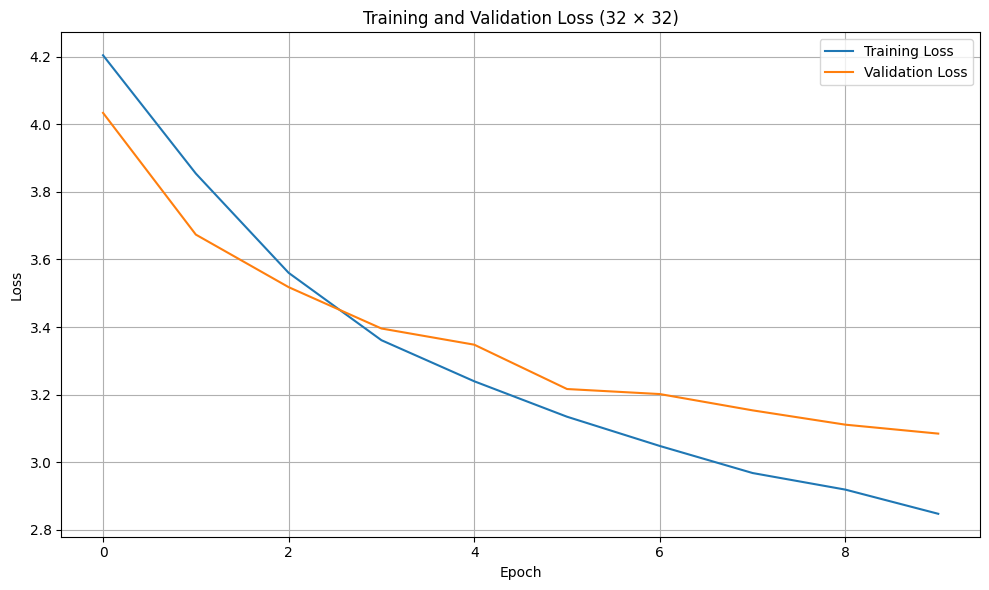

In [ ]:
history = best_result["history"]

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    f"Training and Validation Loss "
    f"({best_result['resolution']})"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

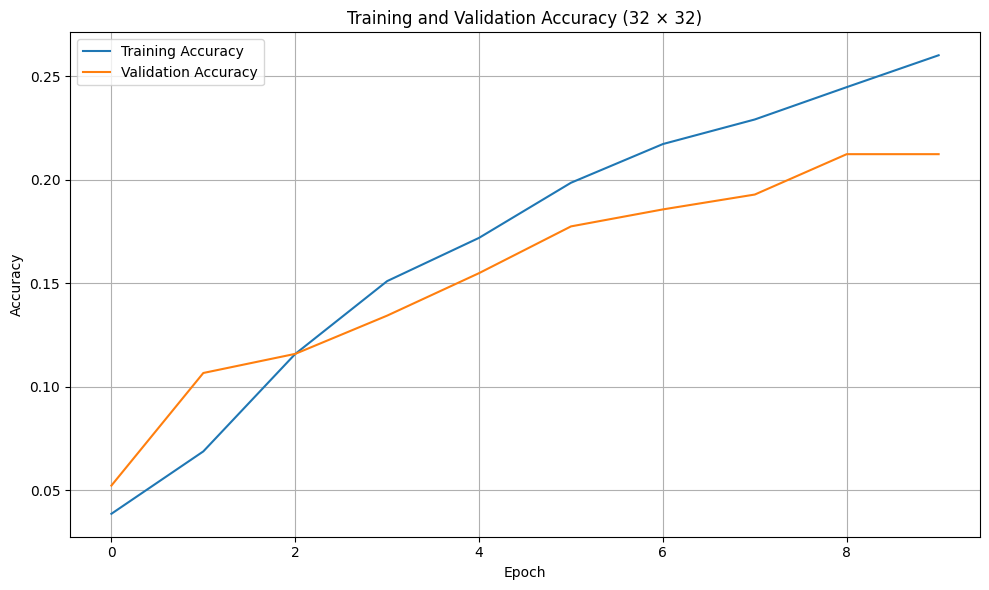

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    f"Training and Validation Accuracy "
    f"({best_result['resolution']})"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

In [ ]:
results_table_formatted = results_table.copy()

for column in [
    "Training Accuracy",
    "Validation Accuracy",
    "Test Accuracy"
]:

    results_table_formatted[column] = (
        results_table_formatted[column] * 100
    ).round(2)


results_table_formatted[
    "Training Time (seconds)"
] = results_table_formatted[
    "Training Time (seconds)"
].round(2)


display(
    results_table_formatted
)

,Resolution,Input Features,Parameters,Training Accuracy,Validation Accuracy,Test Accuracy,Test Loss,Training Time (seconds)
0,32 × 32,3072,403019,26.01,21.23,19.59,3.094355,15.14
1,64 × 64,12288,1582667,7.34,7.90,6.67,3.656231,42.51
2,128 × 128,49152,6301259,2.02,2.05,1.95,4.313210,171.60


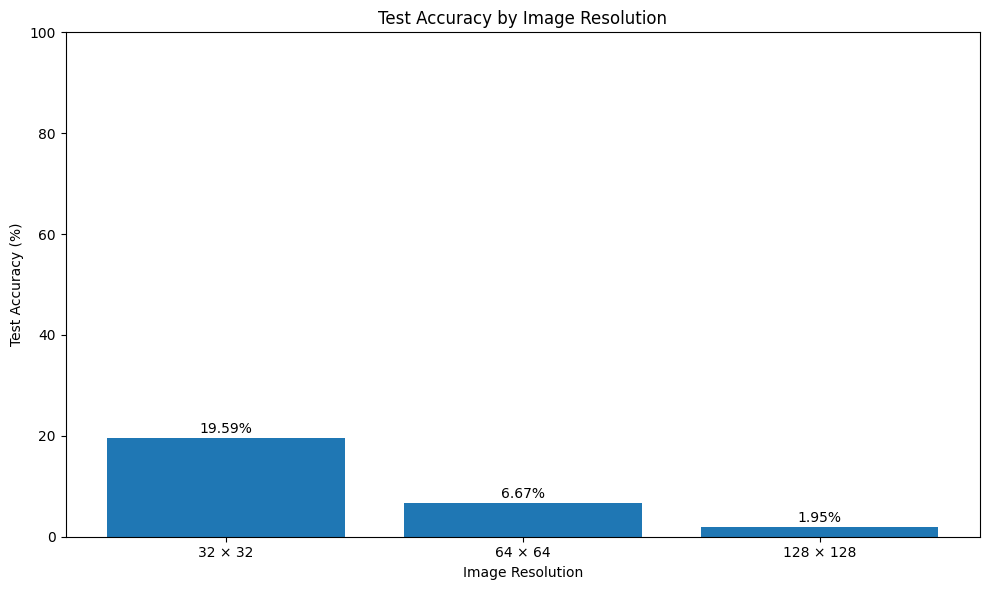

In [ ]:
resolutions = [
    "32 × 32",
    "64 × 64",
    "128 × 128"
]

test_accuracies = [
    result_32["test_accuracy"] * 100,
    result_64["test_accuracy"] * 100,
    result_128["test_accuracy"] * 100
]


plt.figure(figsize=(10, 6))

plt.bar(
    resolutions,
    test_accuracies
)

plt.title(
    "Test Accuracy by Image Resolution"
)

plt.xlabel(
    "Image Resolution"
)

plt.ylabel(
    "Test Accuracy (%)"
)

plt.ylim(
    0,
    100
)

for i, value in enumerate(
    test_accuracies
):

    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )


plt.tight_layout()

plt.show()

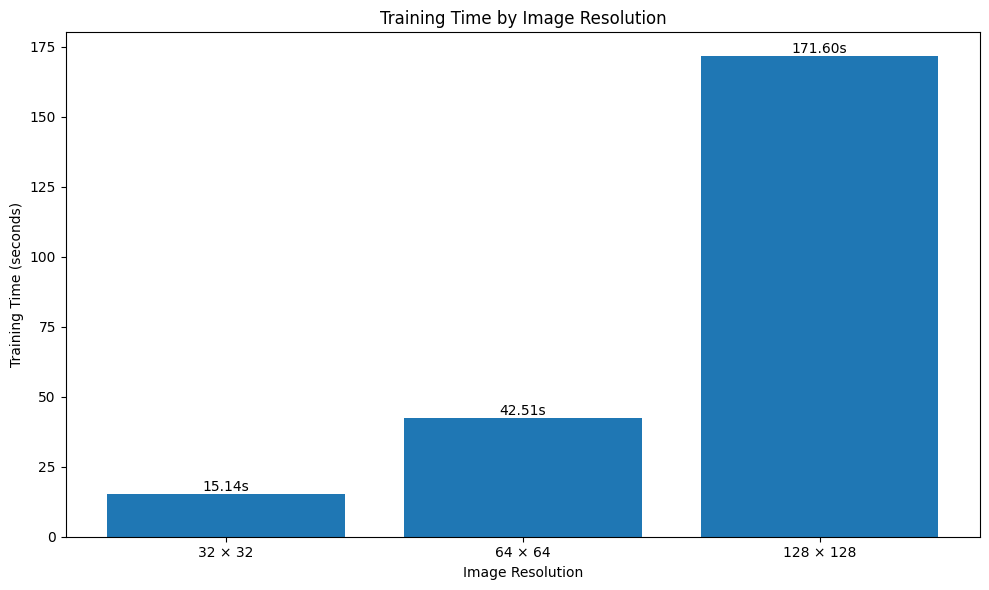

In [ ]:
training_times = [
    result_32["training_time"],
    result_64["training_time"],
    result_128["training_time"]
]


plt.figure(figsize=(10, 6))

plt.bar(
    resolutions,
    training_times
)

plt.title(
    "Training Time by Image Resolution"
)

plt.xlabel(
    "Image Resolution"
)

plt.ylabel(
    "Training Time (seconds)"
)

for i, value in enumerate(
    training_times
):

    plt.text(
        i,
        value,
        f"{value:.2f}s",
        ha="center",
        va="bottom"
    )


plt.tight_layout()

plt.show()

In [ ]:
best_model = best_result["model"]

X_test = best_result["X_test"]

y_test = best_result["y_test"]

test_loss = best_result["test_loss"]

test_accuracy = best_result["test_accuracy"]


print(
    "Best Model Resolution:",
    best_result["resolution"]
)

print(
    "Test Loss:",
    f"{test_loss:.4f}"
)

print(
    "Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)

Best Model Resolution: 32 × 32
Test Loss: 3.0944
Test Accuracy: 19.59%


In [ ]:
predicted_probabilities = (
    best_model.predict(
        X_test,
        verbose=1
    )
)

y_pred = np.argmax(
    predicted_probabilities,
    axis=1
)


print(
    "Predictions generated."
)

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Predictions generated.


In [ ]:
report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)


report_df = pd.DataFrame(
    report
).transpose()


display(
    report_df
)

,precision,recall,f1-score,support
ADONIS,0.615385,0.615385,0.615385,13.000000
AFRICAN GIANT SWALLOWTAIL,0.230769,0.272727,0.250000,11.000000
AMERICAN SNOOT,0.000000,0.000000,0.000000,11.000000
AN 88,0.111111,0.230769,0.150000,13.000000
APPOLLO,0.500000,0.076923,0.133333,13.000000
...,...,...,...,...
YELLOW SWALLOW TAIL,0.500000,0.363636,0.421053,11.000000
ZEBRA LONG WING,0.333333,0.090909,0.142857,11.000000
accuracy,0.195897,0.195897,0.195897,0.195897
macro avg,0.193525,0.189455,0.158154,975.000000


In [ ]:
report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

classification_table = pd.DataFrame({
    "Class": class_names,

    "Precision": [
        report[class_name]["precision"]
        for class_name in class_names
    ],

    "Recall": [
        report[class_name]["recall"]
        for class_name in class_names
    ],

    "F1-Score": [
        report[class_name]["f1-score"]
        for class_name in class_names
    ],

    "Support": [
        report[class_name]["support"]
        for class_name in class_names
    ]
})

classification_table[
    ["Precision", "Recall", "F1-Score"]
] = classification_table[
    ["Precision", "Recall", "F1-Score"]
].round(4)

display(classification_table)

,Class,Precision,Recall,F1-Score,Support
0,ADONIS,0.6154,0.6154,0.6154,13.0
1,AFRICAN GIANT SWALLOWTAIL,0.2308,0.2727,0.2500,11.0
2,AMERICAN SNOOT,0.0000,0.0000,0.0000,11.0
3,AN 88,0.1111,0.2308,0.1500,13.0
4,APPOLLO,0.5000,0.0769,0.1333,13.0
...,...,...,...,...,...
70,ULYSES,0.6471,0.8462,0.7333,13.0
71,VICEROY,0.0000,0.0000,0.0000,12.0
72,WOOD SATYR,1.0000,0.1000,0.1818,10.0
73,YELLOW SWALLOW TAIL,0.5000,0.3636,0.4211,11.0


In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np

report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)


classification_table = pd.DataFrame({

    "Class": class_names,

    "Precision": [
        report[class_name]["precision"]
        for class_name in class_names
    ],

    "Recall": [
        report[class_name]["recall"]
        for class_name in class_names
    ],

    "F1-Score": [
        report[class_name]["f1-score"]
        for class_name in class_names
    ],

    "Support": [
        report[class_name]["support"]
        for class_name in class_names
    ]
})


classification_table[
    ["Precision", "Recall", "F1-Score"]
] = classification_table[
    ["Precision", "Recall", "F1-Score"]
].round(4)


print("=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

display(classification_table)


best_class_index = classification_table[
    "F1-Score"
].idxmax()

best_class = classification_table.loc[
    best_class_index
]


print("\n")
print("=" * 70)
print("BEST PERFORMING CLASS")
print("=" * 70)

print(
    "Class:",
    best_class["Class"]
)

print(
    "Precision:",
    best_class["Precision"]
)

print(
    "Recall:",
    best_class["Recall"]
)

print(
    "F1-Score:",
    best_class["F1-Score"]
)

print(
    "Support:",
    int(best_class["Support"])
)


worst_class_index = classification_table[
    "F1-Score"
].idxmin()

worst_class = classification_table.loc[
    worst_class_index
]


print("\n")
print("=" * 70)
print("MOST DIFFICULT CLASS")
print("=" * 70)

print(
    "Class:",
    worst_class["Class"]
)

print(
    "Precision:",
    worst_class["Precision"]
)

print(
    "Recall:",
    worst_class["Recall"]
)

print(
    "F1-Score:",
    worst_class["F1-Score"]
)

print(
    "Support:",
    int(worst_class["Support"])
)

CLASSIFICATION REPORT


,Class,Precision,Recall,F1-Score,Support
0,ADONIS,0.6154,0.6154,0.6154,13.0
1,AFRICAN GIANT SWALLOWTAIL,0.2308,0.2727,0.2500,11.0
2,AMERICAN SNOOT,0.0000,0.0000,0.0000,11.0
3,AN 88,0.1111,0.2308,0.1500,13.0
4,APPOLLO,0.5000,0.0769,0.1333,13.0
...,...,...,...,...,...
70,ULYSES,0.6471,0.8462,0.7333,13.0
71,VICEROY,0.0000,0.0000,0.0000,12.0
72,WOOD SATYR,1.0000,0.1000,0.1818,10.0
73,YELLOW SWALLOW TAIL,0.5000,0.3636,0.4211,11.0




BEST PERFORMING CLASS
Class: ULYSES
Precision: 0.6471
Recall: 0.8462
F1-Score: 0.7333
Support: 13


MOST DIFFICULT CLASS
Class: AMERICAN SNOOT
Precision: 0.0
Recall: 0.0
F1-Score: 0.0
Support: 11


In [ ]:
correct_indices = np.where(
    y_pred == y_test
)[0]

print("=" * 70)
print("CORRECT PREDICTIONS")
print("=" * 70)

print(
    "Number of correct predictions:",
    len(correct_indices)
)

print(
    "Total test images:",
    len(y_test)
)

print(
    "Correct prediction rate:",
    f"{len(correct_indices) / len(y_test) * 100:.2f}%"
)

CORRECT PREDICTIONS
Number of correct predictions: 191
Total test images: 975
Correct prediction rate: 19.59%


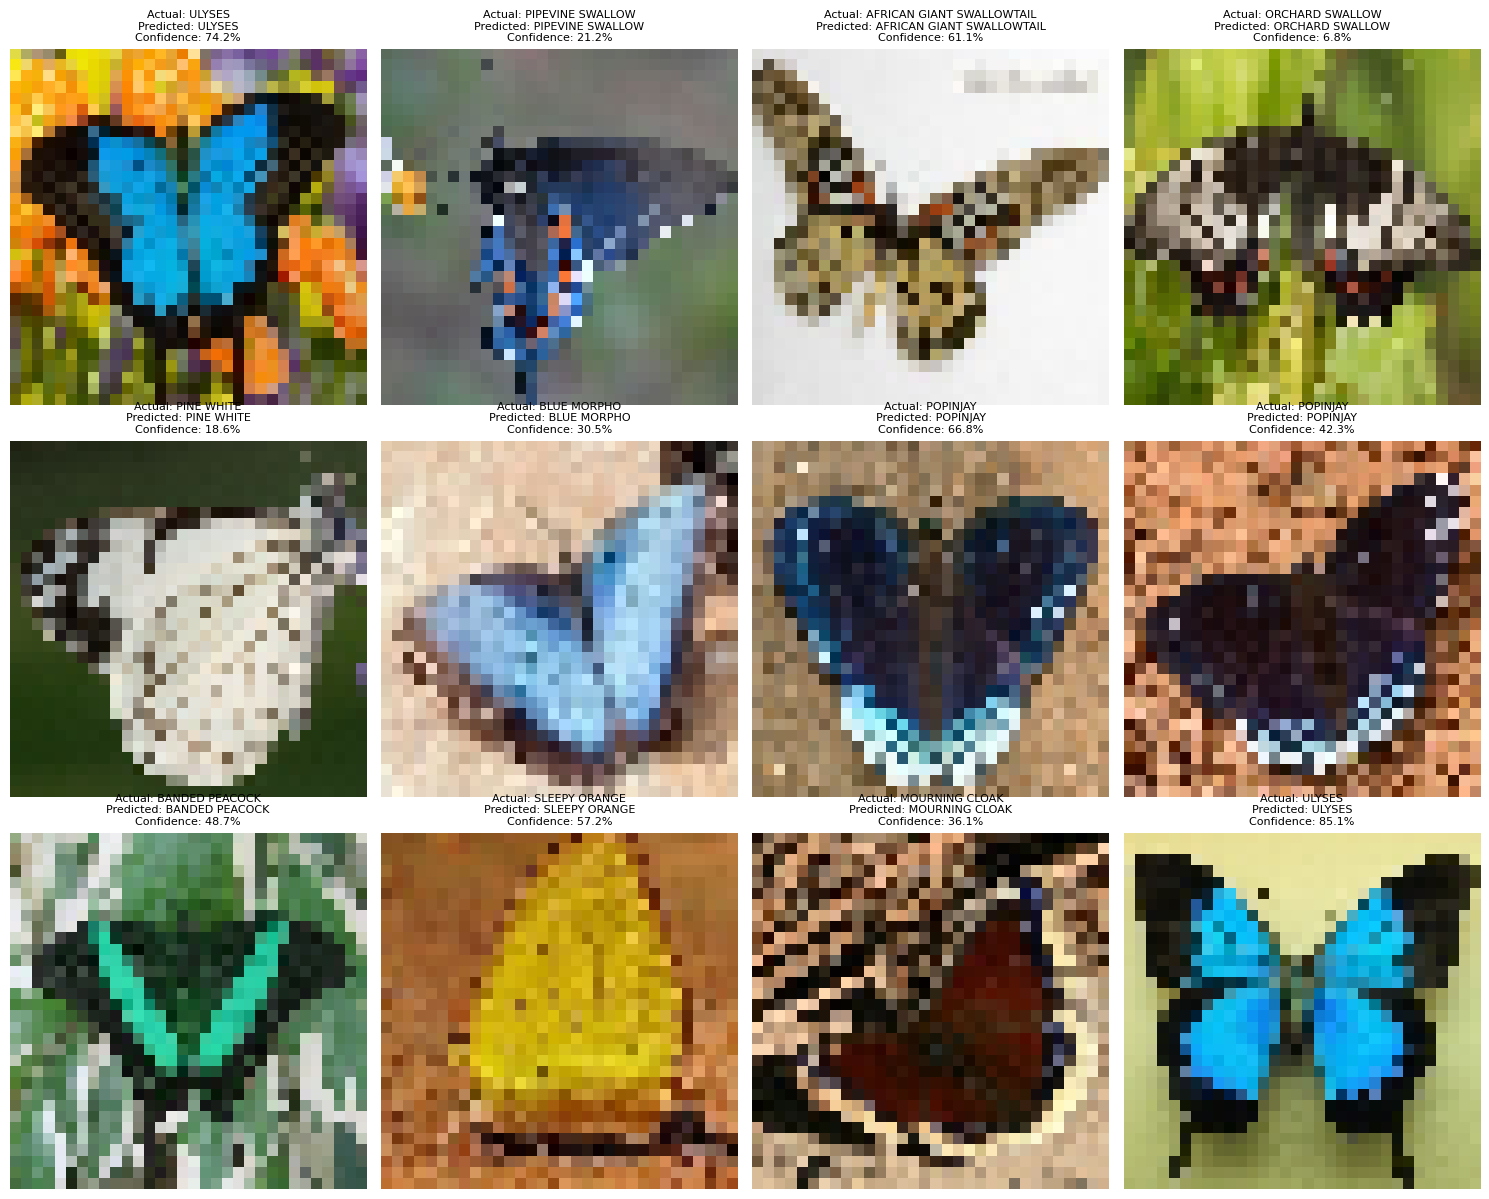

In [ ]:
num_examples = min(
    12,
    len(correct_indices)
)

selected_correct = correct_indices[
    :num_examples
]

plt.figure(
    figsize=(15, 12)
)

for i, idx in enumerate(
    selected_correct
):

    plt.subplot(
        3,
        4,
        i + 1
    )

    plt.imshow(
        X_test[idx]
    )

    actual = class_names[
        y_test[idx]
    ]

    predicted = class_names[
        y_pred[idx]
    ]

    confidence = (
        predicted_probabilities[
            idx,
            y_pred[idx]
        ] * 100
    )

    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.1f}%",
        fontsize=8
    )

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "Figure_8_Correct_Predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
incorrect_indices = np.where(
    y_pred != y_test
)[0]

print("=" * 70)
print("INCORRECT PREDICTIONS")
print("=" * 70)

print(
    "Number of incorrect predictions:",
    len(incorrect_indices)
)

print(
    "Incorrect prediction rate:",
    f"{len(incorrect_indices) / len(y_test) * 100:.2f}%"
)

INCORRECT PREDICTIONS
Number of incorrect predictions: 784
Incorrect prediction rate: 80.41%


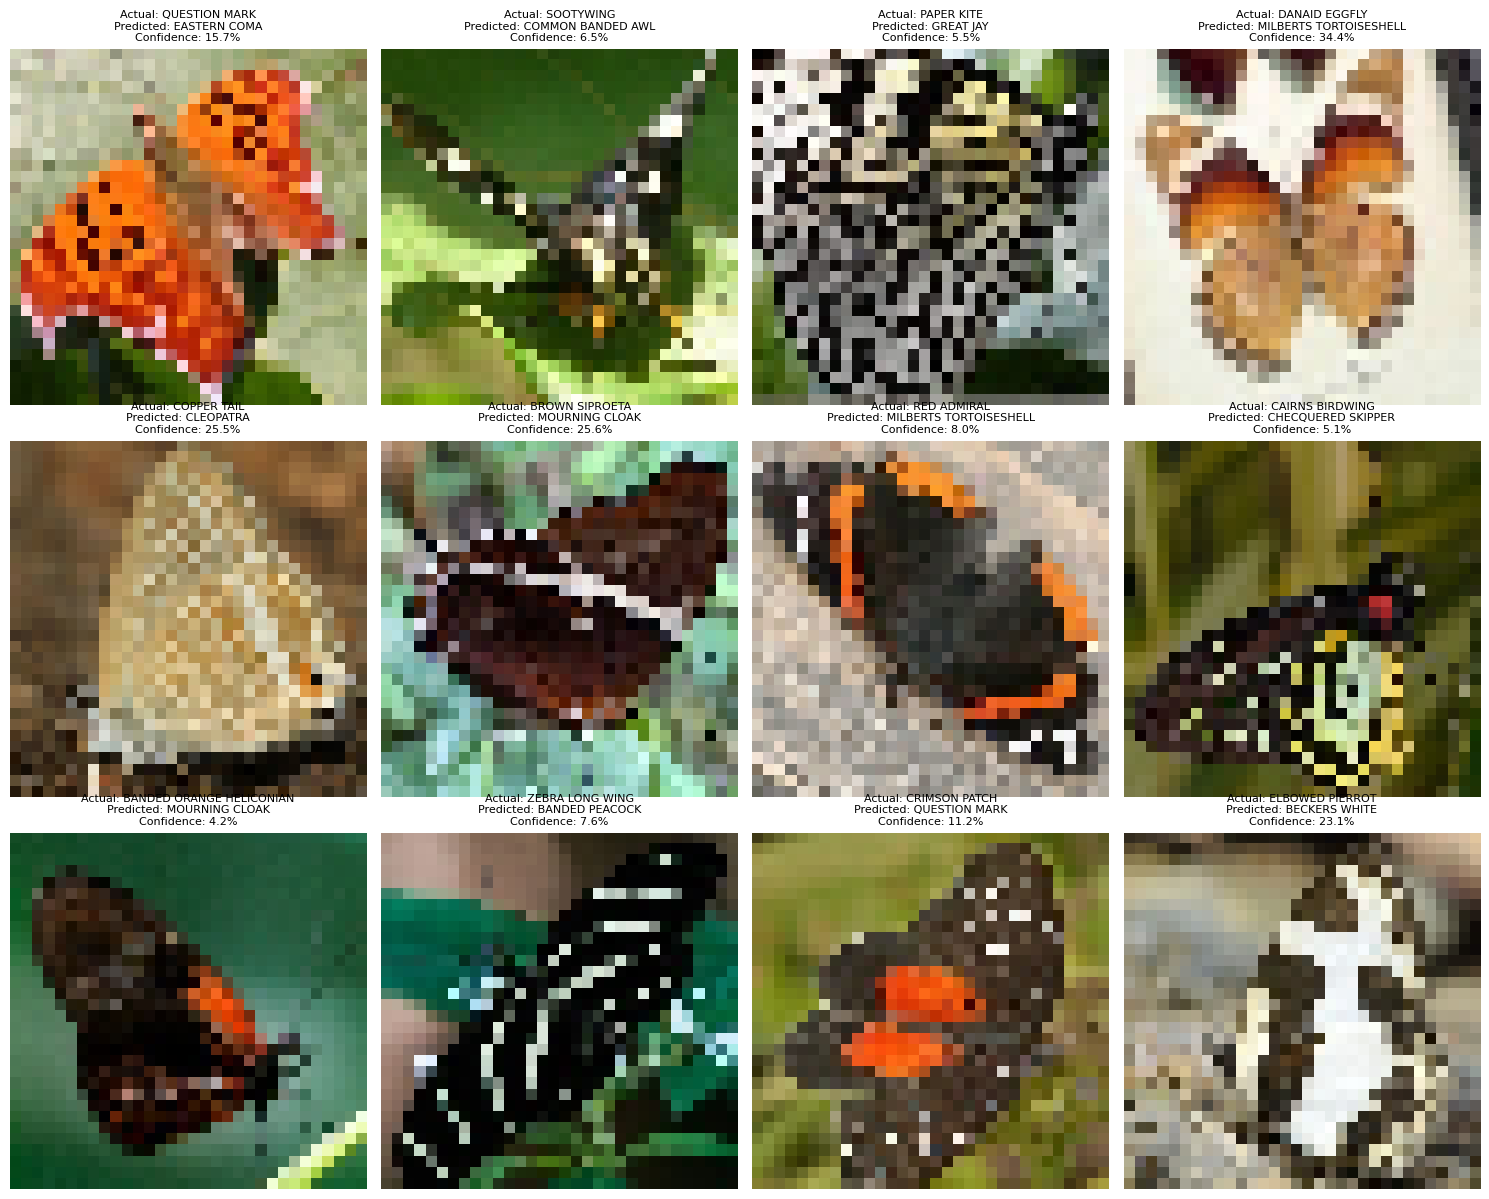

In [ ]:
num_examples = min(
    12,
    len(incorrect_indices)
)

selected_incorrect = incorrect_indices[
    :num_examples
]

plt.figure(
    figsize=(15, 12)
)

for i, idx in enumerate(
    selected_incorrect
):

    plt.subplot(
        3,
        4,
        i + 1
    )

    plt.imshow(
        X_test[idx]
    )

    actual = class_names[
        y_test[idx]
    ]

    predicted = class_names[
        y_pred[idx]
    ]

    confidence = (
        predicted_probabilities[
            idx,
            y_pred[idx]
        ] * 100
    )

    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.1f}%",
        fontsize=8
    )

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "Figure_9_Incorrect_Predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
if len(incorrect_indices) >= 3:

    selected_errors = incorrect_indices[:3]

else:

    selected_errors = incorrect_indices


error_analysis = []

for i, idx in enumerate(
    selected_errors
):

    actual = class_names[
        y_test[idx]
    ]

    predicted = class_names[
        y_pred[idx]
    ]

    confidence = (
        predicted_probabilities[
            idx,
            y_pred[idx]
        ] * 100
    )

    error_analysis.append({

        "Example":
            i + 1,

        "Actual Class":
            actual,

        "Predicted Class":
            predicted,

        "Prediction Confidence (%)":
            round(
                confidence,
                2
            )
    })


error_analysis_df = pd.DataFrame(
    error_analysis
)

display(
    error_analysis_df
)

,Example,Actual Class,Predicted Class,Prediction Confidence (%)
0,1,QUESTION MARK,EASTERN COMA,15.67
1,2,SOOTYWING,COMMON BANDED AWL,6.51
2,3,PAPER KITE,GREAT JAY,5.51


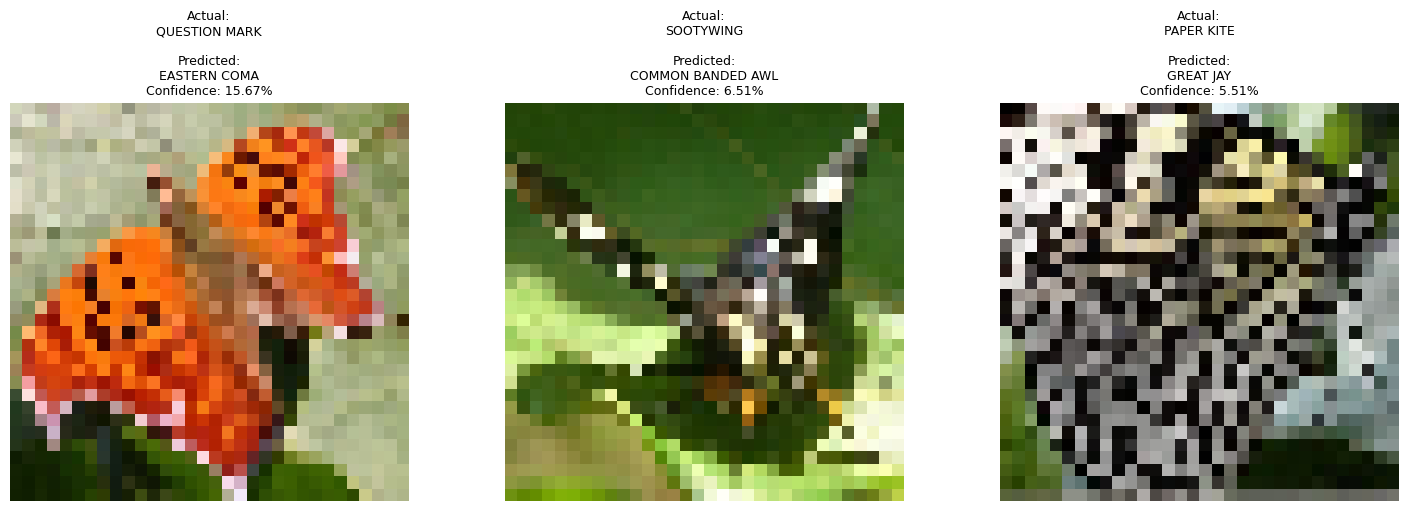

In [ ]:
num_errors = len(selected_errors)

plt.figure(
    figsize=(15, 5)
)

for i, idx in enumerate(
    selected_errors
):

    plt.subplot(
        1,
        num_errors,
        i + 1
    )

    plt.imshow(
        X_test[idx]
    )

    actual = class_names[
        y_test[idx]
    ]

    predicted = class_names[
        y_pred[idx]
    ]

    confidence = (
        predicted_probabilities[
            idx,
            y_pred[idx]
        ] * 100
    )

    plt.title(
        f"Actual:\n{actual}\n\n"
        f"Predicted:\n{predicted}\n"
        f"Confidence: {confidence:.2f}%",
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "Figure_10_Three_Error_Examples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Confusion matrix created.
Matrix shape: (75, 75)


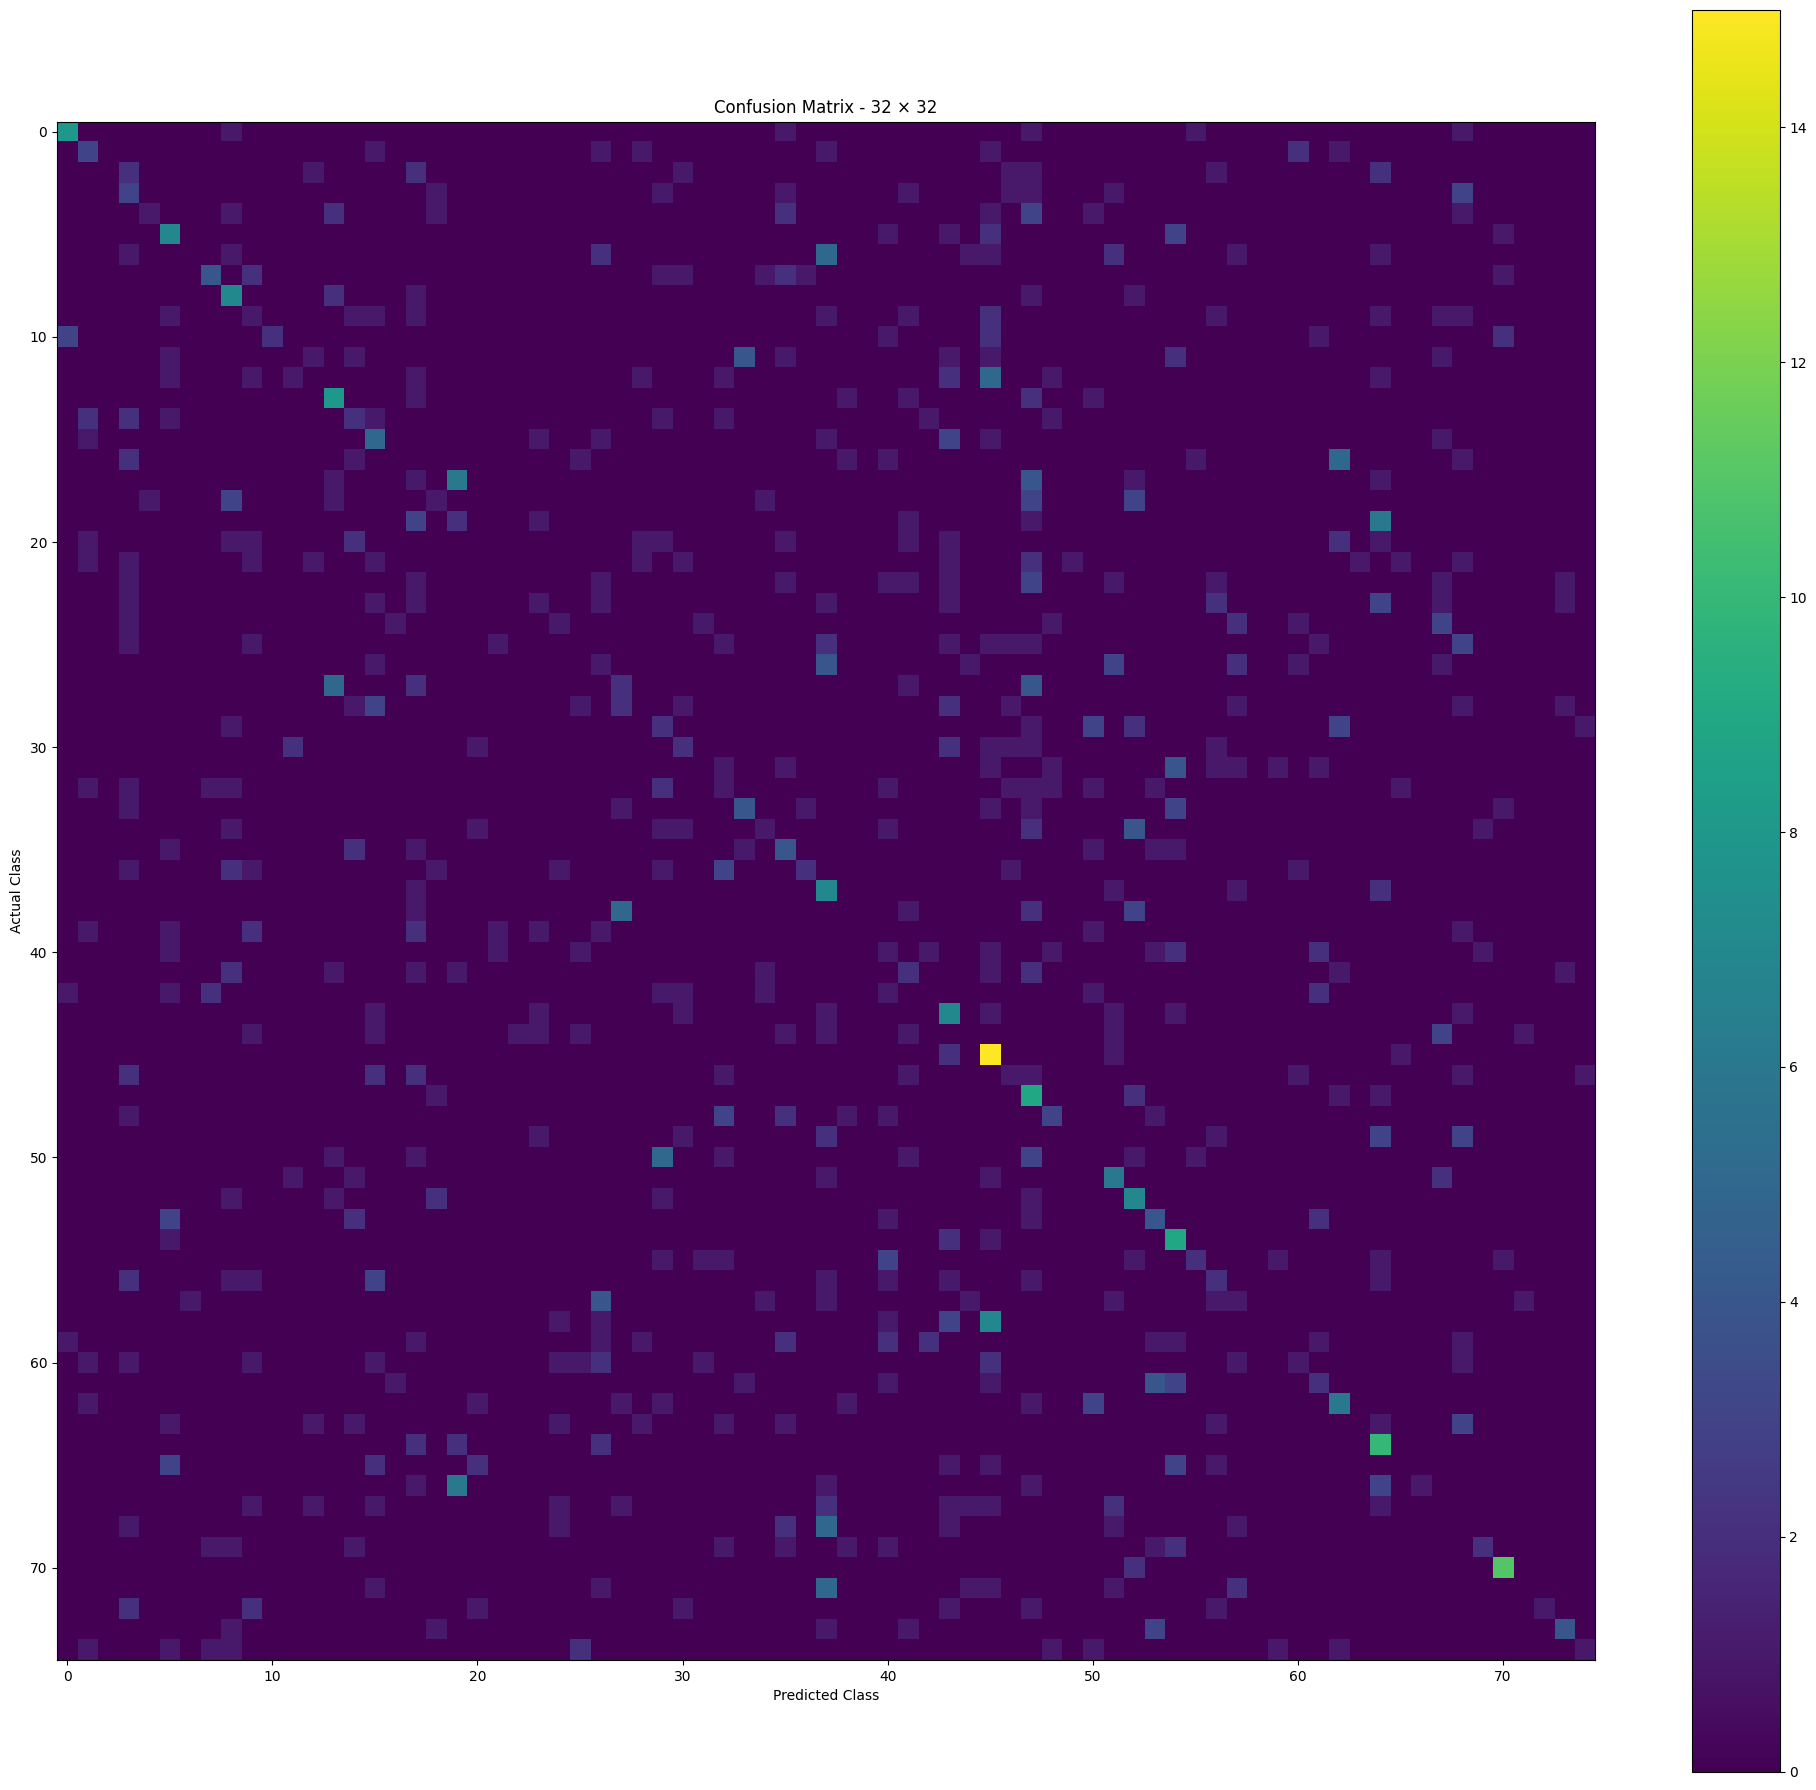

TOP CONFUSING CLASS PAIRS


,Actual Class,Predicted Class,Number of Errors
0,RED ADMIRAL,MOURNING CLOAK,7
1,CLOUDED SULPHUR,SLEEPY ORANGE,6
2,SOUTHERN DOGFACE,CLOUDED SULPHUR,6
3,CLEOPATRA,CLOUDED SULPHUR,6
4,TROPICAL LEAFWING,JULIA,5
5,PAPER KITE,ELBOWED PIERROT,5
6,BROWN SIPROETA,MOURNING CLOAK,5
7,CHESTNUT,SCARCE SWALLOW,5
8,VICEROY,JULIA,5
9,LARGE MARBLE,EASTERN DAPPLE WHITE,5


In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

print("Confusion matrix created.")
print("Matrix shape:", cm.shape)


plt.figure(
    figsize=(20, 18)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.title(
    f"Confusion Matrix - {best_result['resolution']}"
)

plt.colorbar()

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.tight_layout()

plt.show()


confusion_pairs = []

for actual_index in range(NUM_CLASSES):

    for predicted_index in range(NUM_CLASSES):

        if actual_index == predicted_index:
            continue

        count = cm[
            actual_index,
            predicted_index
        ]

        if count > 0:

            confusion_pairs.append({

                "Actual Class":
                    class_names[actual_index],

                "Predicted Class":
                    class_names[predicted_index],

                "Number of Errors":
                    int(count)
            })


if len(confusion_pairs) > 0:

    confusion_pairs_df = pd.DataFrame(
        confusion_pairs
    )

    confusion_pairs_df = (
        confusion_pairs_df
        .sort_values(
            "Number of Errors",
            ascending=False
        )
        .reset_index(drop=True)
    )

    print("=" * 70)
    print("TOP CONFUSING CLASS PAIRS")
    print("=" * 70)

    display(
        confusion_pairs_df.head(10)
    )

else:

    print(
        "No incorrect predictions were found."
    )

In [ ]:
print("=" * 70)
print("ERROR ANALYSIS SUMMARY")
print("=" * 70)

print()

for i, idx in enumerate(
    selected_errors
):

    actual = class_names[
        y_test[idx]
    ]

    predicted = class_names[
        y_pred[idx]
    ]

    confidence = (
        predicted_probabilities[
            idx,
            y_pred[idx]
        ] * 100
    )

    print(
        f"Example {i + 1}:"
    )

    print(
        f"Actual class: {actual}"
    )

    print(
        f"Predicted class: {predicted}"
    )

    print(
        f"Prediction confidence: "
        f"{confidence:.2f}%"
    )

    print(
        "Possible reason: "
        "The model may have difficulty distinguishing "
        "visually similar butterfly classes based on "
        "shape, wing patterns, colors, or other visual features."
    )

    print("-" * 70)

ERROR ANALYSIS SUMMARY

Example 1:
Actual class: QUESTION MARK
Predicted class: EASTERN COMA
Prediction confidence: 15.67%
Possible reason: The model may have difficulty distinguishing visually similar butterfly classes based on shape, wing patterns, colors, or other visual features.
----------------------------------------------------------------------
Example 2:
Actual class: SOOTYWING
Predicted class: COMMON BANDED AWL
Prediction confidence: 6.51%
Possible reason: The model may have difficulty distinguishing visually similar butterfly classes based on shape, wing patterns, colors, or other visual features.
----------------------------------------------------------------------
Example 3:
Actual class: PAPER KITE
Predicted class: GREAT JAY
Prediction confidence: 5.51%
Possible reason: The model may have difficulty distinguishing visually similar butterfly classes based on shape, wing patterns, colors, or other visual features.
----------------------------------------------------------

In [ ]:
!pip install pydot graphviz

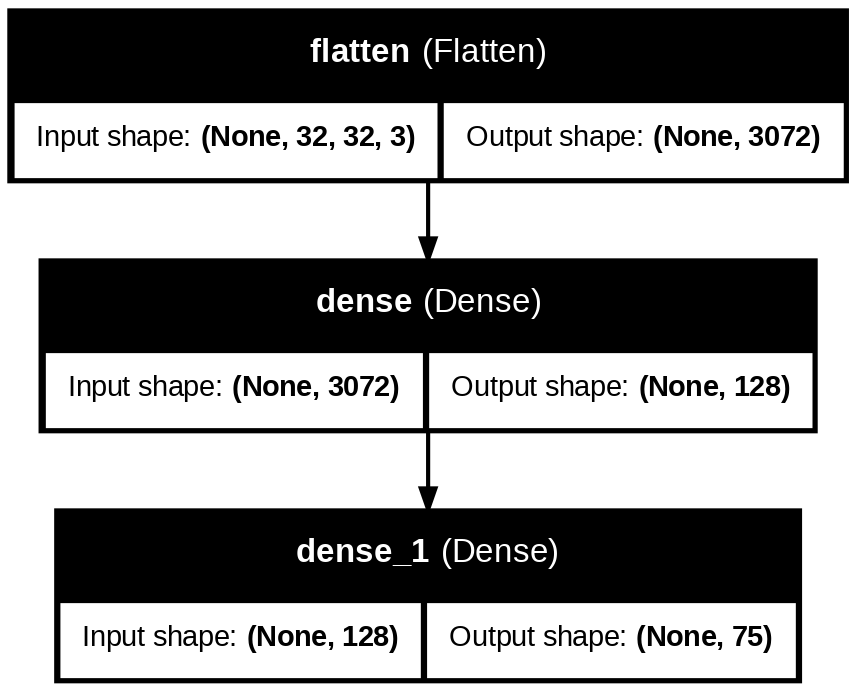

In [ ]:
from tensorflow.keras.utils import plot_model
from IPython.display import Image, display

plot_model(
    best_model,
    to_file="/content/model_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    dpi=150
)

display(Image(filename="/content/model_architecture.png"))

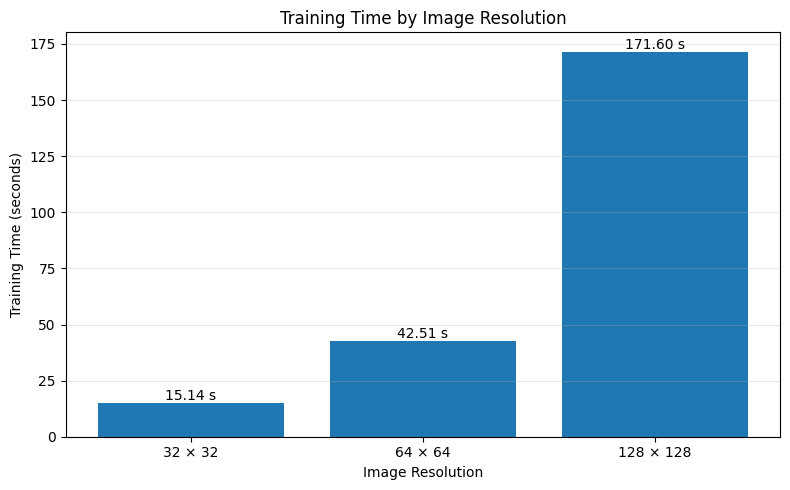

In [ ]:
import matplotlib.pyplot as plt

resolutions = [
    "32 × 32",
    "64 × 64",
    "128 × 128"
]

times = training_times

plt.figure(figsize=(8, 5))

plt.bar(resolutions, times)

plt.xlabel("Image Resolution")
plt.ylabel("Training Time (seconds)")
plt.title("Training Time by Image Resolution")

for i, value in enumerate(times):
    plt.text(
        i,
        value,
        f"{value:.2f} s",
        ha="center",
        va="bottom"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/Figure_6_Training_Time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

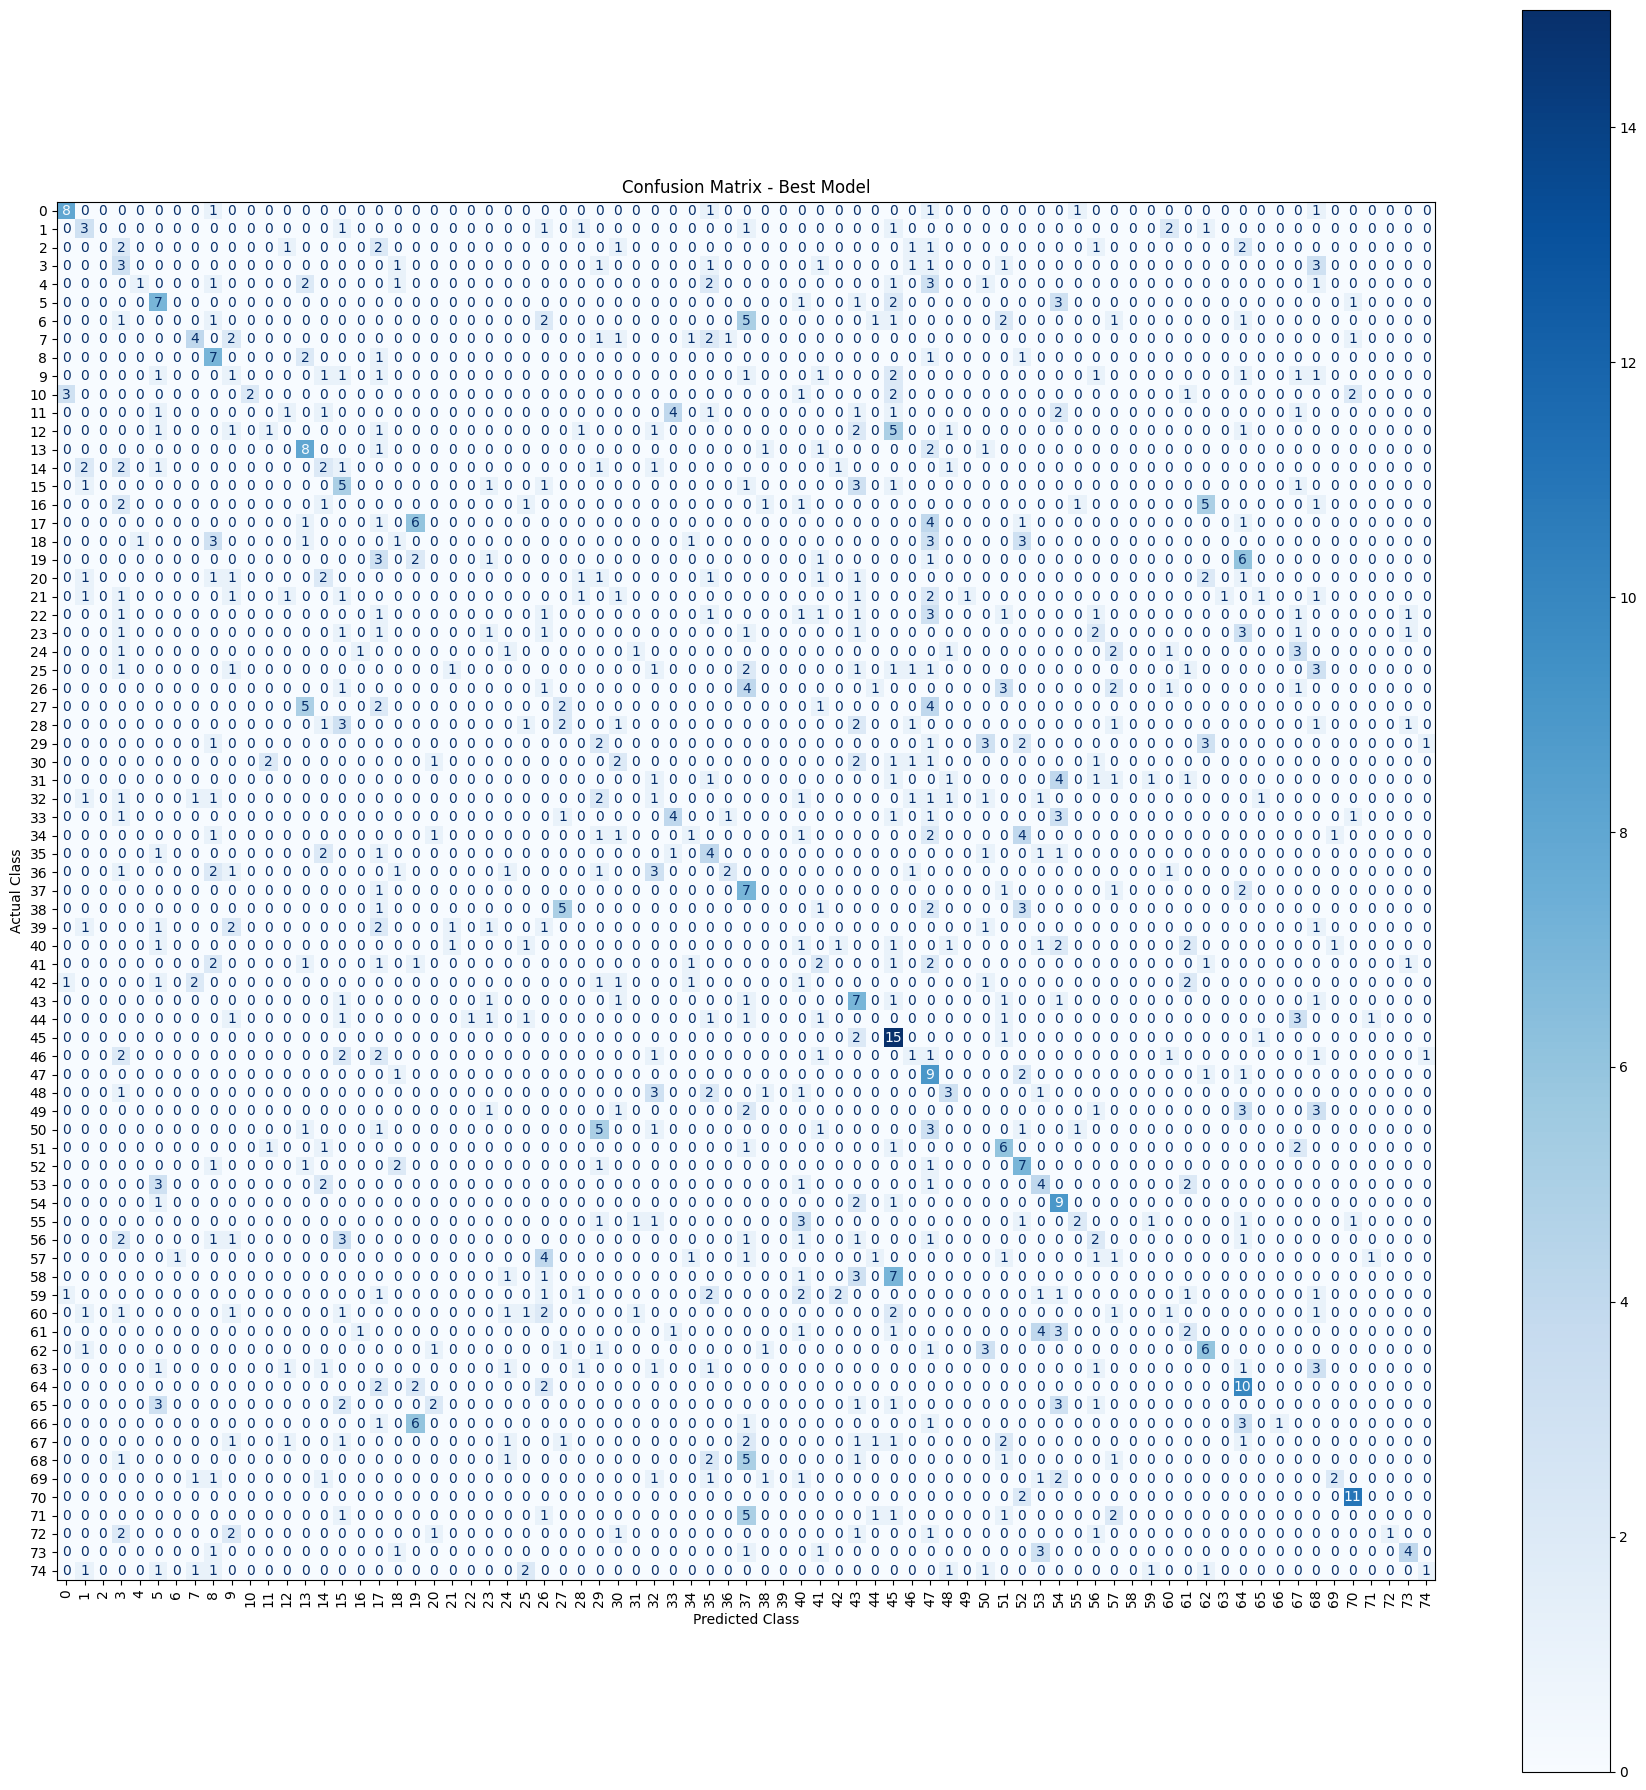

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred_prob = best_model.predict(X_test, verbose=0)

y_pred = np.argmax(y_pred_prob, axis=1)

if len(y_test.shape) > 1 and y_test.shape[1] > 1:
    y_true = np.argmax(y_test, axis=1)
else:
    y_true = np.array(y_test).astype(int)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(75)
)

plt.figure(figsize=(18, 18))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(75)
)

disp.plot(
    ax=plt.gca(),
    cmap="Blues",
    xticks_rotation="vertical",
    colorbar=True
)

plt.title("Confusion Matrix - Best Model")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    "/content/Figure_7_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

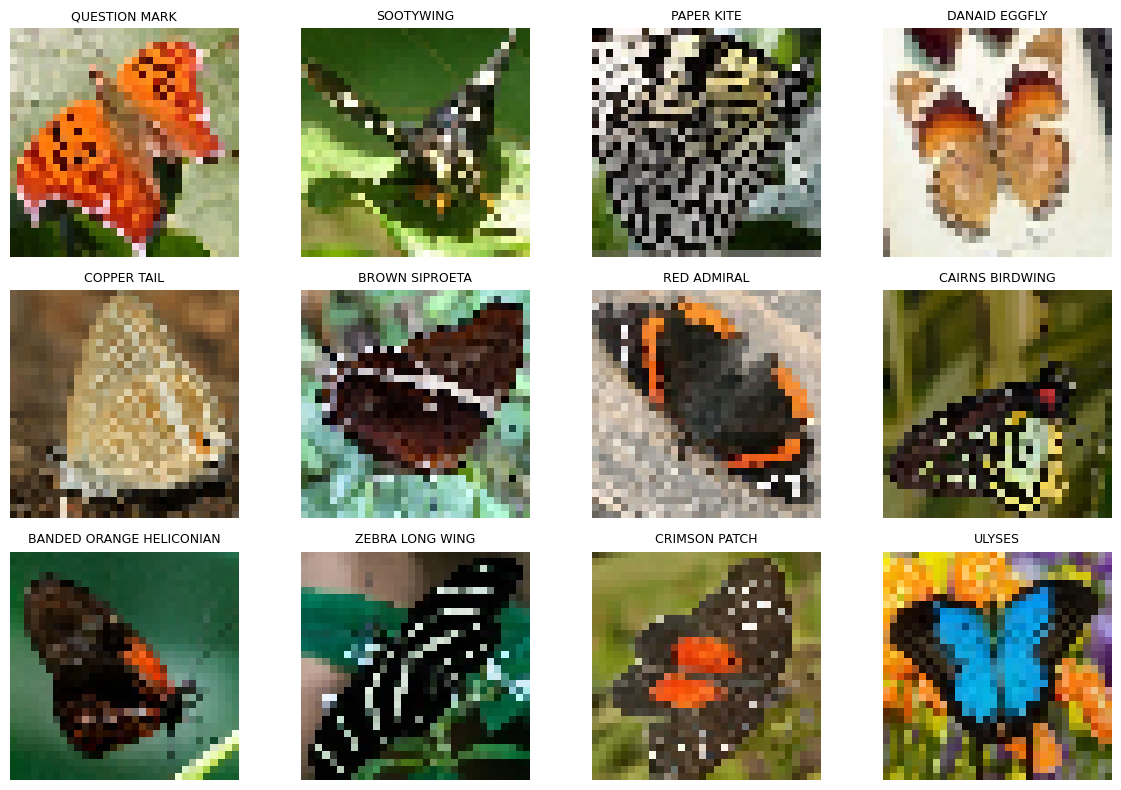

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i])
    plt.axis("off")
    plt.title(class_names[y_true[i]], fontsize=9)

plt.tight_layout()
plt.savefig("/content/Appendix_B1_Dataset_Samples.png", dpi=300)
plt.show()